In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as px
%matplotlib inline
from sklearn.model_selection import train_test_split,cross_validate,StratifiedKFold,GridSearchCV,RandomizedSearchCV
from sklearn.metrics import mean_squared_error,mean_absolute_error,r2_score
from xgboost import XGBRegressor
from sklearn.preprocessing import LabelEncoder

In [2]:
data = pd.read_csv("Ecommerce.csv")

In [3]:
data

,Date,Product_Category,Price,Discount,Customer_Segment,Marketing_Spend,Units_Sold
0,01-01-2023,Sports,932.80,35.82,Occasional,6780.38,32
1,02-01-2023,Toys,569.48,3.60,Premium,6807.56,16
2,03-01-2023,Home Decor,699.68,3.56,Premium,3793.91,27
3,04-01-2023,Toys,923.27,0.61,Premium,9422.75,29
4,05-01-2023,Toys,710.17,47.83,Premium,1756.83,17
...,...,...,...,...,...,...,...
995,22-09-2025,Fashion,740.06,49.06,Regular,1890.83,34
996,23-09-2025,Electronics,517.10,28.48,Premium,8011.66,21
997,24-09-2025,Electronics,683.43,12.98,Occasional,3408.51,19
998,25-09-2025,Sports,51.26,21.85,Occasional,7335.62,26


In [6]:
encoder = LabelEncoder()
collection = ['Product_Category','Customer_Segment']
for i,datas in enumerate(collection):
    data[datas+str(i)] = encoder.fit_transform(data[datas])

In [9]:
data.drop(["Date","Product_Category","Customer_Segment"],inplace=True,axis=1)

In [11]:
data.to_csv("modified.csv",index=False)

In [19]:
data["year"] = pd.to_datetime(data['Date']).dt.year
data["Month"] = pd.to_datetime(data['Date']).dt.month
data["Month_Name"] = pd.to_datetime(data['Date']).dt.month_name()

In [20]:
data

,Date,Product_Category,Price,Discount,Customer_Segment,Marketing_Spend,Units_Sold,year,Month,Month_Name
0,01-01-2023,Sports,932.80,35.82,Occasional,6780.38,32,2023,1,January
1,02-01-2023,Toys,569.48,3.60,Premium,6807.56,16,2023,2,February
2,03-01-2023,Home Decor,699.68,3.56,Premium,3793.91,27,2023,3,March
3,04-01-2023,Toys,923.27,0.61,Premium,9422.75,29,2023,4,April
4,05-01-2023,Toys,710.17,47.83,Premium,1756.83,17,2023,5,May
...,...,...,...,...,...,...,...,...,...,...
995,22-09-2025,Fashion,740.06,49.06,Regular,1890.83,34,2025,9,September
996,23-09-2025,Electronics,517.10,28.48,Premium,8011.66,21,2025,9,September
997,24-09-2025,Electronics,683.43,12.98,Occasional,3408.51,19,2025,9,September
998,25-09-2025,Sports,51.26,21.85,Occasional,7335.62,26,2025,9,September


In [16]:
units_sold_by_cate = data.groupby(['Product_Category'])['Units_Sold'].sum()
print(units_sold_by_cate)


colors = ['red','yellow','violet','green','black']

fig = px.Figure([px.Bar(x=units_sold_by_cate.index, y=units_sold_by_cate.values,marker_color =colors)])
fig.show()

Product_Category
Electronics    6210
Fashion        5650
Home Decor     5643
Sports         6125
Toys           6003
Name: Units_Sold, dtype: int64


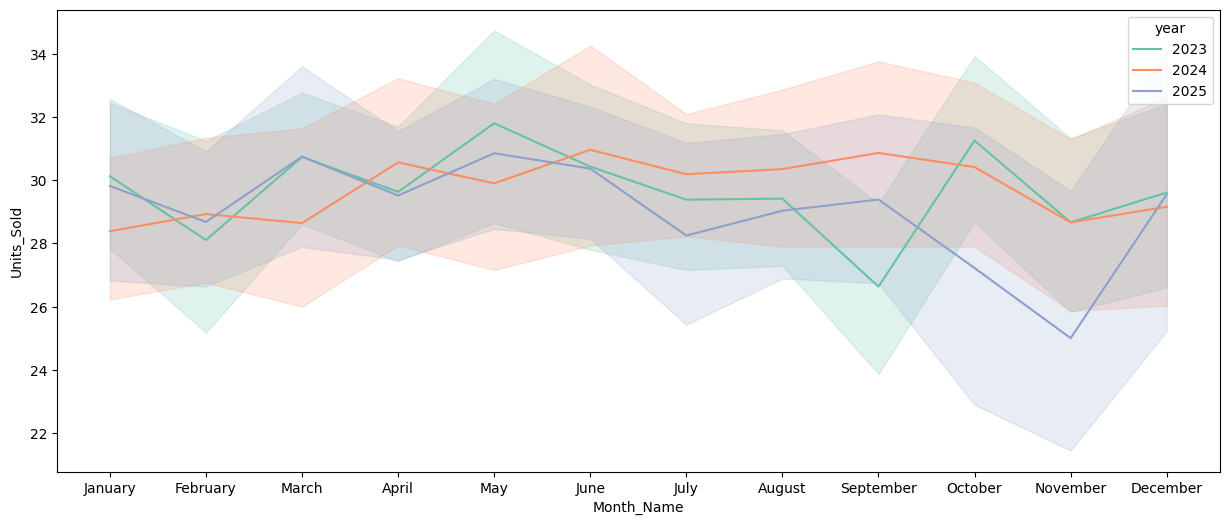

In [25]:

plt.figure(figsize=(15,6))
sns.lineplot(data=data,x='Month_Name',y='Units_Sold',hue='year',palette='Set2')
plt.show()


In [39]:
discount_by_year = data.groupby(['year'])['Discount'].sum()

In [36]:
discount_by_year

,year,Discount
0,2023,9224.40
1,2024,9131.13
2,2025,6564.22


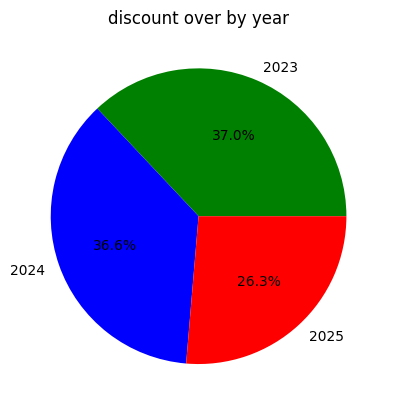

In [45]:
plt.pie(discount_by_year.values,labels=discount_by_year.index,autopct='%1.1f%%',colors=['green','blue','red'])
plt.title("discount over by year")
plt.show()

In [64]:
customer_segment = data['Customer_Segment'].value_counts().reset_index()


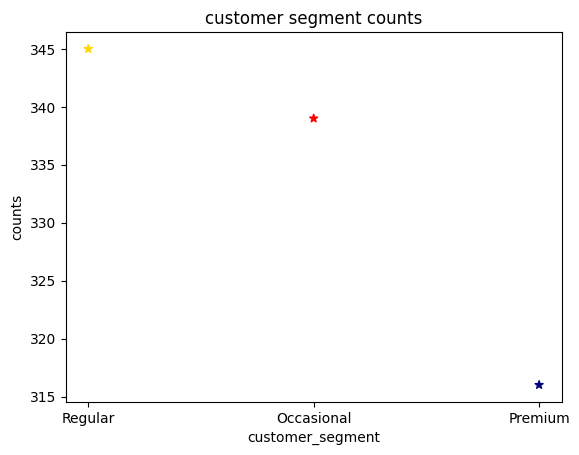

In [73]:
plt.scatter(customer_segment['index'],customer_segment['Customer_Segment'],marker="*",c=['gold','red','navy'])
plt.title("customer segment counts")
plt.xlabel("customer_segment")
plt.ylabel("counts")

plt.show()

<Figure size 1500x1000 with 0 Axes>

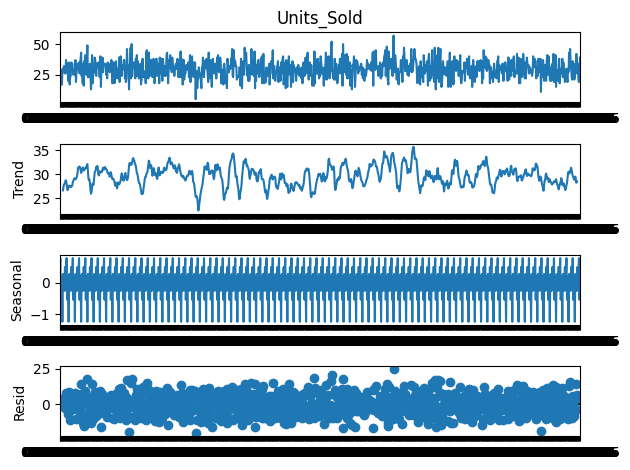

In [76]:
from statsmodels.tsa.seasonal import seasonal_decompose

data_new = data.set_index("Date")

decomposition = seasonal_decompose(data_new['Units_Sold'],model='additive',period=12)

plt.figure(figsize=(15,10))
decomposition.plot()
plt.show()

In [77]:
data_new

,Product_Category,Price,Discount,Customer_Segment,Marketing_Spend,Units_Sold,year,Month,Month_Name
Date,,,,,,,,,
01-01-2023,Sports,932.80,35.82,Occasional,6780.38,32,2023,1,January
02-01-2023,Toys,569.48,3.60,Premium,6807.56,16,2023,2,February
03-01-2023,Home Decor,699.68,3.56,Premium,3793.91,27,2023,3,March
04-01-2023,Toys,923.27,0.61,Premium,9422.75,29,2023,4,April
05-01-2023,Toys,710.17,47.83,Premium,1756.83,17,2023,5,May
...,...,...,...,...,...,...,...,...,...
22-09-2025,Fashion,740.06,49.06,Regular,1890.83,34,2025,9,September
23-09-2025,Electronics,517.10,28.48,Premium,8011.66,21,2025,9,September
24-09-2025,Electronics,683.43,12.98,Occasional,3408.51,19,2025,9,September


In [2]:
from sklearn.preprocessing import StandardScaler

In [6]:
data_1 = pd.read_csv("modified.csv")

In [7]:
data_1

,Price,Discount,Marketing_Spend,Units_Sold,Product_Category0,Customer_Segment1
0,932.80,35.82,6780.38,32,3,0
1,569.48,3.60,6807.56,16,4,1
2,699.68,3.56,3793.91,27,2,1
3,923.27,0.61,9422.75,29,4,1
4,710.17,47.83,1756.83,17,4,1
...,...,...,...,...,...,...
995,740.06,49.06,1890.83,34,1,2
996,517.10,28.48,8011.66,21,0,1
997,683.43,12.98,3408.51,19,0,0
998,51.26,21.85,7335.62,26,3,0


In [8]:
X = data_1.drop(columns="Units_Sold").values
scaler = StandardScaler()

In [18]:
X = scaler.fit_transform(X)

In [19]:
X.shape

(1000, 5)

In [20]:
y = data_1['Units_Sold'].values


(1000, 1)

In [21]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [22]:
model = XGBRegressor()

model.fit(X_train,y_train)

XGBRegressor(base_score=0.5, booster='gbtree', callbacks=None,
             colsample_bylevel=1, colsample_bynode=1, colsample_bytree=1,
             early_stopping_rounds=None, enable_categorical=False,
             eval_metric=None, gamma=0, gpu_id=-1, grow_policy='depthwise',
             importance_type=None, interaction_constraints='',
             learning_rate=0.300000012, max_bin=256, max_cat_to_onehot=4,
             max_delta_step=0, max_depth=6, max_leaves=0, min_child_weight=1,
             missing=nan, monotone_constraints='()', n_estimators=100, n_jobs=0,
             num_parallel_tree=1, predictor='auto', random_state=0, reg_alpha=0,
             reg_lambda=1, ...)

In [23]:
y_pred = model.predict(X_test)

In [24]:
type(y_test)

numpy.ndarray

In [25]:
r2_score = r2_score(y_test,y_pred)

In [26]:
print(r2_score*100)

-12.819716252435654


In [27]:
print(mean_squared_error(y_test,y_pred))

61.01716149360573
